from https://patonv.medium.com/bayesian-a-b-testing-in-python-a-step-by-step-walkthrough-ad1bd6358b24

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import beta

#no pymc needed since using conjugate priors

In [9]:
#Version A
visitorsA = 2000
conversionsA = 220

#Version B
visitorsB = 800
conversionsB = 95

In [10]:
#prior parameters, neutral beta 
alphaPrior = 1
betaPrior = 1

In [11]:
#posteriors
posteriorA = beta(alphaPrior + conversionsA, betaPrior + visitorsA - conversionsA)
posteriorB = beta(alphaPrior + conversionsB, betaPrior + visitorsB - conversionsB)

In [14]:
#posterior sampling
samples = 1000
samplesA = posteriorA.rvs(samples)
samplesB = posteriorB.rvs(samples)

Text(0.5, 0, 'Conversion Rate of Version A')

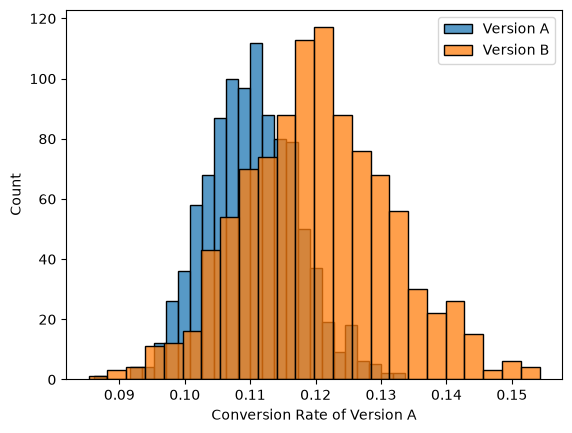

In [22]:
sns.histplot(data=samplesA, label="Version A")
sns.histplot(data=samplesB, label="Version B")
plt.legend()
plt.xlabel("Conversion Rate of Version A")

In [32]:
BoverA = np.mean(samplesB > samplesA)
print(f"Probability that Variant B is better than A: {BoverA:.2%}")

Probability that Variant B is better than A: 78.00%


### Same problem but with MCMC instead of conjugate approach

In [28]:
import pymc as pm
import arviz as az

with pm.Model() as model:
    pA = pm.Beta('pA', alpha=1, beta=1)
    pB = pm.Beta('pB', alpha=1, beta=1)
    obsA = pm.Binomial('obsA', n=2000, p=pA, observed = 220)
    obsB = pm.Binomial('obsB', n=950, p=pB, observed = 135)

    delta = pm.Deterministic('delta', pB - pA)
    trace = pm.sample(2000, return_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [pA, pB]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 42 seconds.


,mean,sd,hdi_2.5%,hdi_97.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
pA,0.110,0.007,0.097,0.124,0.0,0.0,8726.0,5886.0,1.0
pB,0.143,0.011,0.121,0.165,0.0,0.0,8533.0,5426.0,1.0
delta,0.033,0.013,0.006,0.058,0.0,0.0,8639.0,5829.0,1.0


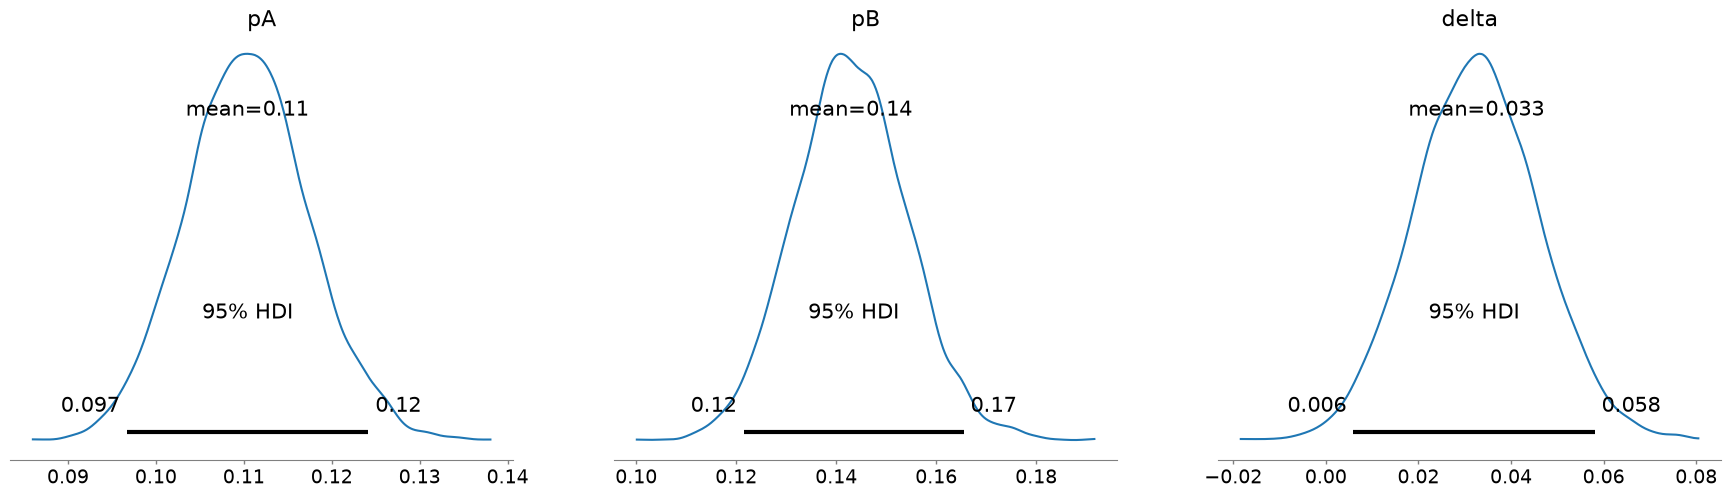

In [30]:
az.plot_posterior(trace, var_names=["pA", "pB", "delta"], hdi_prob=0.95)
az.summary(trace, var_names=["pA", "pB", "delta"], hdi_prob=0.95)

In [31]:
delta_samples = trace.posterior['delta'].values.flatten()
prob_B_beats_A = (delta_samples > 0).mean()
print(f"Probability that Variant B is better than A: {prob_B_beats_A:.2%}")

Probability that Variant B is better than A: 99.35%
